# Nettoyage des données – Prix des denrées sur les marchés du Bénin

Le PAM (Programme Alimentaire Mondial) relève chaque mois les prix des denrées sur les marchés du Bénin. Dans ce notebook, on découvre ces données, on vérifie leur qualité et on les nettoie. À la fin, on enregistre un fichier propre, qui servira pour l'analyse (`02_eda.ipynb`) et la modélisation.

Le notebook suit quatre parties :
1. Découverte des données
2. Qualité des données et nettoyage
3. Choix du périmètre d'étude
4. Prix aberrants

**Source :** HDX – *Benin - Food Prices* (PAM), copie Hugging Face `electricsheepafrica/africa-wfp-food-prices-for-benin`.

# Partie 1 – Découverte des données

## 1.1 Chargement

Les données sont en deux fichiers `.parquet`, train et test. Ce découpage est aléatoire et ne nous sert pas, donc on recolle tout. On refera notre propre découpage dans le temps au moment de la modélisation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_parquet("../data/train.parquet")
test = pd.read_parquet("../data/test.parquet")

df = pd.concat([train, test], ignore_index=True)
print(train.shape, test.shape, df.shape)
df.head()

(91529, 18) (22883, 18) (114412, 18)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,esa_source,esa_processed
0,2020-08-15,Alibori,Karimama,Karimama,2771,12.07,3.18,cereals and tubers,Millet,73,KG,actual,Retail,XOF,200.00,0.36,HDX,2026-04-06
1,2025-07-15,Oueme,Adjohoun,Azowlissè,2554,6.67,2.49,oil and fats,Oil (palm),62,L,actual,Retail,XOF,837.50,1.49,HDX,2026-04-06
2,2021-07-15,Borgou,Sinende,Sinendé,1750,10.34,2.38,cereals and tubers,Rice (imported),64,KG,actual,Retail,XOF,478.72,0.87,HDX,2026-04-06
3,2025-05-15,Atlantique,Allada,Sékou,2777,6.63,2.22,pulses and nuts,"Groundnuts (small, unshelled)",557,KG,actual,Retail,XOF,1216.25,2.11,HDX,2026-04-06
4,2023-03-15,Zou,Cove,Covè,2765,7.22,2.34,cereals and tubers,Sorghum (red),282,KG,actual,Retail,XOF,344.83,0.57,HDX,2026-04-06


## 1.2 Types des colonnes et valeurs manquantes

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114412 entries, 0 to 114411
Data columns (total 18 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   date           114412 non-null  datetime64[ns]
 1   admin1         114412 non-null  object        
 2   admin2         114412 non-null  object        
 3   market         114412 non-null  object        
 4   market_id      114412 non-null  int64         
 5   latitude       114412 non-null  float64       
 6   longitude      114412 non-null  float64       
 7   category       114412 non-null  object        
 8   commodity      114412 non-null  object        
 9   commodity_id   114412 non-null  int64         
 10  unit           114412 non-null  object        
 11  priceflag      114412 non-null  object        
 12  pricetype      114412 non-null  object        
 13  currency       114412 non-null  object        
 14  price          114412 non-null  float64       
 15  

## 1.3 Nombre de valeurs différentes par colonne

Pour voir combien on a de marchés, de produits, de dates, et repérer les colonnes qui ont la même valeur partout.

In [3]:
df.nunique()

date               254
admin1              12
admin2              46
market              51
market_id           51
latitude            48
longitude           42
category             6
commodity           53
commodity_id        53
unit                 2
priceflag            1
pricetype            2
currency             1
price            13978
usdprice          1659
esa_source           1
esa_processed        1
dtype: int64

## Bilan de la partie 1

- 114 412 lignes et 18 colonnes, sans aucune valeur manquante. La colonne `date` est déjà au bon format.
- 51 marchés, 53 produits et 254 dates différentes.
- 4 colonnes n'ont qu'une seule valeur (`priceflag`, `currency`, `esa_source`, `esa_processed`) : elles ne servent à rien.
- `pricetype` a deux valeurs : il faudra choisir.
- Attention : pas de valeur manquante ne veut pas dire pas de trou. Un mois sans relevé, c'est une ligne qui n'existe pas.

# Partie 2 – Qualité des données et nettoyage

## 2.1 Prix de détail ou prix de gros ?

In [4]:
df["pricetype"].value_counts()

pricetype
Retail       114196
Wholesale       216
Name: count, dtype: int64

Presque tout est en prix de détail. Avant de supprimer les prix de gros, on regarde ce qu'ils contiennent : quels produits, quels marchés, et si ces produits ont aussi un prix de détail sur le même marché.

In [5]:
gros = df[df["pricetype"] == "Wholesale"]
print(gros.groupby(["commodity", "market"]).size())

malan = df[(df["market"] == "Malanville (CBM)") & (df["pricetype"] == "Retail")]
print(gros["commodity"].unique())
print(malan["commodity"].unique())

commodity        market          
Maize            Malanville (CBM)    48
Millet           Malanville (CBM)    73
Rice (imported)  Malanville (CBM)    72
Sorghum          Malanville (CBM)    13
Wheat            Malanville (CBM)    10
dtype: int64
['Rice (imported)' 'Sorghum' 'Millet' 'Maize' 'Wheat']
['Fish (tilapia)' 'Rice (imported)' 'Plantains' 'Groundnuts (Bambara)'
 'Sorghum (red)' 'Coconut (dried)' 'Wheat flour (imported)'
 'Beans (white)' 'Cassava flour' 'Maize (white)' 'Peppers (red, dry)'
 'Potatoes' 'Carrots' 'Rice (local)' 'Soybeans' 'Yam (white)'
 'Cassava meal (tapioca)' 'Sweet potatoes' 'Cassava meal (gari)' 'Papaya'
 'Yam (flour)' 'Onions' 'Oranges' 'Yam (dry)' 'Cassava (fresh)' 'Cabbage'
 'Yam' 'Cassava (cossette)' 'Groundnuts (small, unshelled)' 'Okra (fresh)'
 'Lemons' 'Cassava meal (gari, fine)' 'Maize (yellow)' 'Tomatoes'
 'Fish (fresh, silvi)' 'Millet' 'Wheat' 'Oil (groundnut)' 'Oil (palm)'
 'Sorghum' 'Rice (Broken, local)' 'Peas (green, dry)' 'Oil (palm nut)'
 'Ri

Les 216 prix de gros viennent tous de Malanville, et concernent 5 céréales qu'on retrouve aussi en prix de détail sur ce marché (le maïs y est noté « Maize (white) » et « Maize (yellow) »). On garde donc uniquement le détail, sans perdre de produit.

## 2.2 Suppression des prix de gros et des colonnes inutiles

In [6]:
df = df[df["pricetype"] == "Retail"]
df = df.drop(columns=["pricetype", "priceflag", "currency", "esa_source", "esa_processed"])
df.shape

(114196, 13)

## 2.3 Doublons

On cherche les lignes identiques, puis les cas où un même produit a plusieurs prix sur le même marché le même mois.

In [7]:
print(df.duplicated().sum())

cle = ["date", "market", "commodity", "unit"]
print(df.duplicated(subset=cle).sum())

0
0


Aucun doublon : on a bien un seul prix par produit, par marché et par mois.

## 2.4 Les noms de produits

Certains produits ont des noms proches (Maize, Maize (white)…). On regarde la période de chaque nom : si un nom s'arrête quand un autre commence, c'est un changement de nom et il faudrait les fusionner.

In [8]:
produits = df.groupby("commodity")["date"].agg(["count", "min", "max"])
produits.sort_index()

,count,min,max
commodity,,,
Beans (black),765,2020-04-15,2026-02-15
Beans (red),2684,2019-01-15,2026-02-15
Beans (white),3617,2007-01-15,2026-02-15
Cabbage,1505,2020-04-15,2026-02-15
Carrots,1986,2019-01-15,2026-02-15
Cassava (cossette),1241,2020-04-15,2026-02-15
Cassava (fresh),1028,2020-04-15,2026-02-15
Cassava flour,1201,2020-04-15,2026-02-15
Cassava meal (gari),4096,2007-02-15,2026-02-15


Les noms proches se chevauchent dans le temps (par exemple `Maize` de 2013 à 2019 et `Maize (white)` de 2007 à 2026) : ce sont des produits différents, on ne fusionne rien. On remarque aussi que la plupart des produits ne démarrent qu'en 2019 ou 2020.

## Bilan de la partie 2

- On garde seulement les prix de détail : 114 196 lignes et 13 colonnes.
- Pas de doublon, pas de nom de produit à fusionner.
- Le vrai sujet, c'est la couverture dans le temps : beaucoup de produits n'existent qu'à partir de 2019-2020.

# Partie 3 – Choix du périmètre d'étude

## 3.1 Depuis quand les données sont-elles denses ?

In [9]:
df.groupby(df["date"].dt.year).agg(releves=("price", "size"), marches=("market", "nunique"), produits=("commodity", "nunique"))

,releves,marches,produits
date,,,
2007,51,1,5
2008,47,1,5
2009,44,1,5
2010,49,1,5
2011,46,1,5
2012,86,2,5
2013,122,4,7
2014,370,21,7
2015,977,21,7


Avant 2019, on a souvent un seul marché et 5 produits. À partir de 2019, on passe à une cinquantaine de marchés et de produits par an. On garde donc les données à partir de janvier 2019. On garde quand même une copie complète pour regarder le long terme plus tard.

In [10]:
df_complet = df.copy()
df = df[df["date"] >= "2019-01-01"]
df.shape

(111432, 13)

## 3.2 Combien de mois par série ?

Une série, c'est un produit sur un marché (par exemple le maïs blanc à Dantokpa). Depuis janvier 2019, il y a 86 mois possibles.

In [11]:
series = df.groupby(["commodity", "market"])["date"].agg(["count", "min", "max"])
print(len(series))
series["count"].describe()

2312


count    2312.000000
mean       48.197232
std        25.202804
min         1.000000
25%        29.000000
50%        58.000000
75%        69.000000
max        85.000000
Name: count, dtype: float64

On garde les séries d'au moins 48 mois (4 ans) qui vont au moins jusqu'en 2025, pour avoir assez d'historique et pouvoir les tester sur la fin de la période.

In [12]:
bonnes = series[(series["count"] >= 48) & (series["max"] >= "2025-01-01")]
print(len(bonnes))
print(bonnes.index.get_level_values("commodity").nunique(), "produits")
print(bonnes.index.get_level_values("market").nunique(), "marchés")

1390
49 produits
50 marchés


## 3.3 Les produits phares

Pour rester simple, on travaille sur quelques produits de base. On regarde sur combien de marchés chaque produit a une bonne série.

In [13]:
bonnes.groupby("commodity").size().sort_values(ascending=False)

commodity
Sorghum (red)                    49
Cassava meal (gari)              49
Oil (groundnut)                  48
Onions                           47
Cassava meal (tapioca)           47
Tomatoes                         47
Groundnuts (Bambara)             45
Peppers (red, dry)               44
Rice (imported)                  44
Groundnuts (small, unshelled)    44
Oranges                          43
Okra (fresh)                     43
Fish (fresh, silvi)              42
Soybeans                         42
Wheat flour (imported)           41
Maize (white)                    40
Beans (white)                    39
Lemons                           38
Cassava meal (gari, fine)        37
Oil (palm)                       37
Beans (red)                      35
Millet                           35
Leafy vegetables                 34
Coconut (dried)                  33
Yam (white)                      30
Yam                              27
Rice (local)                     25
Sorghum           

On retient 7 produits, très consommés et suivis sur beaucoup de marchés :
- gari, riz importé, maïs blanc et haricot blanc, qui ont en plus un historique depuis 2007 ;
- la tomate, un produit frais et très saisonnier ;
- l'huile d'arachide, touchée par la hausse des prix de 2022 (attention, elle est au litre) ;
- l'oignon, lui aussi frais et saisonnier, dont une bonne partie vient du Niger et du Burkina.

In [14]:
phares = ["Cassava meal (gari)", "Rice (imported)", "Maize (white)", "Beans (white)", "Tomatoes", "Oil (groundnut)", "Onions"]
bonnes_phares = bonnes[bonnes.index.get_level_values("commodity").isin(phares)].index

df = df.set_index(["commodity", "market"])
df = df[df.index.isin(bonnes_phares)].reset_index()
df = df.sort_values(["commodity", "market", "date"])

print(df.shape)
print(df.groupby(["commodity", "unit"])["market"].nunique())

(21464, 13)
commodity            unit
Beans (white)        KG      39
Cassava meal (gari)  KG      49
Maize (white)        KG      40
Oil (groundnut)      L       48
Onions               KG      47
Rice (imported)      KG      44
Tomatoes             KG      47
Name: market, dtype: int64


## Bilan de la partie 3

- On garde la période de janvier 2019 à février 2026.
- On garde 7 produits phares et seulement leurs séries assez longues (nombre de lignes et de séries à reprendre de la sortie ci-dessus).
- Chaque produit n'a qu'une seule unité.

# Partie 4 – Prix aberrants

## 4.1 Premier repérage

On cherche les prix plus de 3 fois au-dessus ou en dessous de la médiane de leur produit, et on regarde sur quels marchés ils tombent.

In [15]:
mediane = df.groupby("commodity")["price"].transform("median")
ratio = df["price"] / mediane

bizarres = df[(ratio > 3) | (ratio < 1/3)]
print(len(bizarres))
bizarres.groupby(["commodity", "market"]).size().sort_values(ascending=False).head(15)

262


commodity            market     
Onions               Covè           18
Tomatoes             Tatonnoukon    17
                     Covè           12
Onions               Dassa-Zoumè    10
Cassava meal (gari)  Azovè           9
Tomatoes             Dogbo           9
Cassava meal (gari)  Kétou           8
                     Ouesse          8
Tomatoes             Zinvié          7
Onions               Kalalé          7
Tomatoes             Kétou           7
Onions               Dasso           7
Tomatoes             Dassa-Zoumè     6
                     Kpedekpo        6
                     Azowlissè       6
dtype: int64

La plupart concernent la tomate, sur beaucoup de marchés : c'est surtout un produit très instable. Mais certains marchés reviennent souvent (tomate à Tatonnoukon et Covè, gari à Azovè, Ouesse et Kétou). On compare leurs prix à la médiane nationale : s'ils suivent les mêmes mouvements, ce sont de vrais prix.

## 4.2 La tomate à Tatonnoukon et Covè

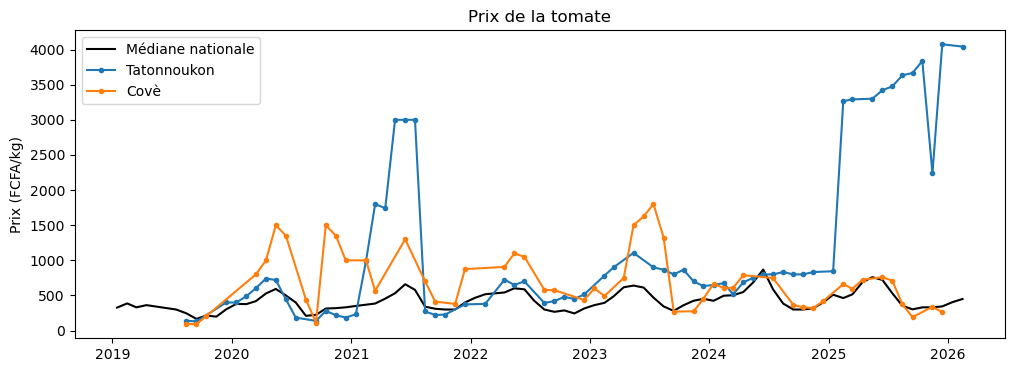

In [16]:
tomate = df[df["commodity"] == "Tomatoes"]
mediane_nat = tomate.groupby("date")["price"].median()

plt.figure(figsize=(12, 4))
plt.plot(mediane_nat, label="Médiane nationale", color="black")
for m in ["Tatonnoukon", "Covè"]:
    serie = tomate[tomate["market"] == m].set_index("date")["price"]
    plt.plot(serie, label=m, marker=".")
plt.ylabel("Prix (FCFA/kg)")
plt.title("Prix de la tomate")
plt.legend()
plt.show()

Covè a des pics plus forts que la moyenne, mais qui tombent aux mêmes moments que le reste du pays : ce sont de vrais prix. À Tatonnoukon, le prix reste bloqué vers 3 000 FCFA/kg en 2021, puis saute à plus de 3 300 FCFA/kg à partir de 2025, alors que le reste du pays ne bouge pas. Ça ressemble à une erreur ou à un changement d'unité. Comme ça tombe en pleine période de test, on retire toute la série.

In [17]:
retrait = (df["commodity"] == "Tomatoes") & (df["market"] == "Tatonnoukon")
print(retrait.sum())

df = df[~retrait]
df.shape

66


(21398, 13)

## 4.3 Le gari à Azovè, Ouesse et Kétou

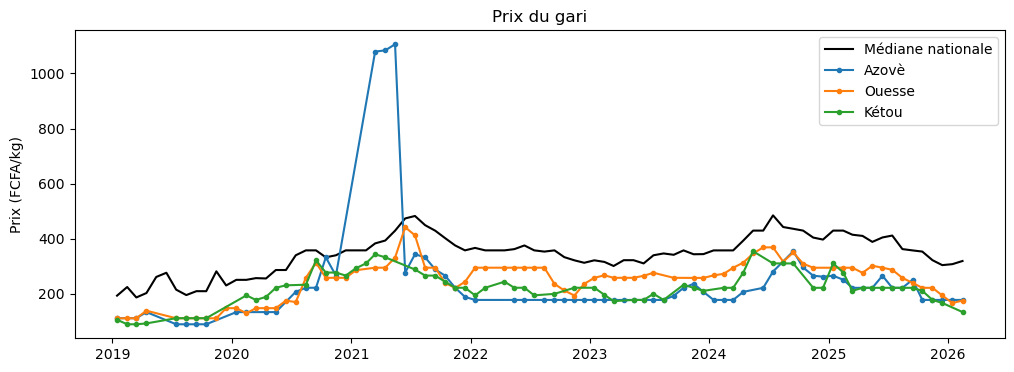

In [18]:
gari = df[df["commodity"] == "Cassava meal (gari)"]
mediane_nat = gari.groupby("date")["price"].median()

plt.figure(figsize=(12, 4))
plt.plot(mediane_nat, label="Médiane nationale", color="black")
for m in ["Azovè", "Ouesse", "Kétou"]:
    serie = gari[gari["market"] == m].set_index("date")["price"]
    plt.plot(serie, label=m, marker=".")
plt.ylabel("Prix (FCFA/kg)")
plt.title("Prix du gari")
plt.legend()
plt.show()

Les trois marchés sont un peu moins chers que la moyenne du pays (ce sont des zones de production de manioc), mais ils suivent les mêmes mouvements. Seul Azovè a un pic à plus de 1 000 FCFA/kg début 2021 que personne d'autre n'a. On supprime juste ces mois-là.

In [19]:
erreur = (df["commodity"] == "Cassava meal (gari)") & (df["market"] == "Azovè") & (df["price"] > 1000)
print(df[erreur][["date", "price"]])

df = df[~erreur]
df.shape

            date    price
315   2021-03-15  1079.65
17709 2021-04-15  1084.07
19382 2021-05-15  1106.19


(21395, 13)

## 4.4 Vérification sur tous les marchés

On compare maintenant chaque prix à la médiane du même produit **le même mois**. Comme ça, une hausse de saison n'est pas prise pour une erreur, puisque tous les marchés montent ensemble.

In [20]:
med_mois = df.groupby(["commodity", "date"])["price"].transform("median")
df["ratio"] = df["price"] / med_mois

suspects = df[(df["ratio"] > 3) | (df["ratio"] < 1/3)]
print(len(suspects))
suspects[["date", "market", "commodity", "price", "ratio"]]

125


,date,market,commodity,price,ratio
9600,2021-09-15,Banikoara,Beans (white),234.08,0.330626
5601,2020-03-15,Dangbo,Maize (white),575.76,3.646589
19873,2022-05-15,Bembèrèkè,Onions,1220.00,3.234573
12180,2020-10-15,Cobly,Onions,140.00,0.261072
2099,2020-11-15,Cobly,Onions,187.33,0.315171
...,...,...,...,...,...
4450,2023-05-15,Tchaourou,Tomatoes,197.00,0.309020
12206,2024-06-15,Tchaourou,Tomatoes,281.00,0.319500
20706,2025-05-15,Tchaourou,Tomatoes,245.50,0.327189
13754,2019-07-15,Zè,Tomatoes,76.00,0.253333


Avant l'ajout de l'oignon, il restait 59 prix suspects sur 18 201 (0,3 %), presque tous sur la tomate. *(À mettre à jour avec la nouvelle sortie, et à vérifier pour l'oignon.)* Les écarts sont modérés et durent souvent plusieurs mois (Dassa-Zoumè en 2022, Dasso en 2024) : ce sont de vraies variations locales, on les garde. Deux cas sont isolés sur un seul mois : le maïs à Dangbo en mars 2020 et la tomate à Djougou en juin 2024. On regarde les mois autour.

In [21]:
cas = [("Maize (white)", "Dangbo", "2020-03-15"), ("Tomatoes", "Djougou", "2024-06-15")]

for produit, marche, date in cas:
    serie = df[(df["commodity"] == produit) & (df["market"] == marche)].set_index("date")
    d = pd.Timestamp(date)
    print(produit, "-", marche)
    print(serie.loc[d - pd.DateOffset(months=3): d + pd.DateOffset(months=3), ["price", "ratio"]])
    print()

Maize (white) - Dangbo
             price     ratio
date                        
2019-12-15  159.09  1.235555
2020-01-15  159.09  1.032717
2020-03-15  575.76  3.646589
2020-04-15  181.82  1.103478
2020-05-15  227.27  1.248874
2020-06-15  250.00  1.357147

Tomatoes - Djougou
              price     ratio
date                         
2024-03-15   725.00  1.461576
2024-04-15   700.00  1.312508
2024-05-15  1650.00  2.426471
2024-06-15  3300.00  3.752132
2024-07-15  1477.50  2.532134
2024-08-15   468.75  1.239669
2024-09-15   300.00  1.000000



Le maïs à Dangbo passe de 159 à 576 FCFA/kg puis retombe à 182 le mois suivant : c'est un pic isolé sur un produit stable, sûrement une erreur, on le supprime. La tomate à Djougou monte et redescend petit à petit sur plusieurs mois (700, 1 650, 3 300, 1 478, 469) : c'est une vraie pénurie locale, on la garde.

In [22]:
erreur = (df["commodity"] == "Maize (white)") & (df["market"] == "Dangbo") & (df["date"] == "2020-03-15")
df = df[~erreur]
df.shape

(21394, 14)

## 4.5 Sauvegarde des données propres

On enregistre le jeu de données nettoyé, pour que l'analyse et la modélisation partent du même fichier.

In [23]:
df = df.drop(columns=["ratio"])
df.to_parquet("../data/prix_propres.parquet", index=False)
df.shape

(21394, 13)

## Bilan de la partie 4

- On a retiré la série tomate de Tatonnoukon (66 lignes), 3 mois de gari à Azovè et 1 mois de maïs à Dangbo.
- Les autres prix suspects sont de vraies variations locales de la tomate : on les garde.
- *(À vérifier : le maximum de l'oignon, à 3 972 FCFA/kg, soit 9 fois sa médiane.)*
- Les données propres sont dans `data/prix_propres.parquet`.